# 03 — Business Insights & Power BI Exports

**Goal:** Produce final KPI, funnel, cohort, churn and revenue tables for the
Power BI dashboard and summarize the business story.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

processed = Path("../data/processed")

user_analysis = pd.read_csv(processed / "user_analysis_master.csv")

for col in [
    "signup_date", "trial_start_date", "subscription_date",
    "cancel_date", "first_session", "last_session"
]:
    if col in user_analysis.columns:
        user_analysis[col] = pd.to_datetime(user_analysis[col], errors="coerce")


## 1. Executive KPIs


In [2]:
signups = user_analysis["user_id"].nunique()
activated = user_analysis["activated"].sum()
trials = user_analysis["trial"].sum()
paid = user_analysis["paid"].sum()
churned = user_analysis["churned"].sum()

activation_rate = activated / signups * 100
trial_conversion_rate = trials / activated * 100
paid_conversion_rate = paid / trials * 100
overall_conversion_rate = paid / signups * 100
churn_rate = churned / paid * 100

active_paid = user_analysis[
    (user_analysis["paid"] == 1) &
    (user_analysis["churned"] == 0)
].copy()

current_mrr = active_paid["monthly_price"].fillna(0).sum()

kpi_summary = pd.DataFrame({
    "metric": [
        "Total Signups", "Activated Users", "Trial Users", "Paid Users",
        "Churned Users", "Activation Rate", "Trial Conversion Rate",
        "Paid Conversion Rate", "Overall Signup to Paid Rate",
        "Churn Rate", "Current MRR"
    ],
    "value": [
        signups, activated, trials, paid, churned,
        round(activation_rate, 2),
        round(trial_conversion_rate, 2),
        round(paid_conversion_rate, 2),
        round(overall_conversion_rate, 2),
        round(churn_rate, 2),
        round(current_mrr, 2)
    ]
})

kpi_summary


,metric,value
0,Total Signups,10000.00
1,Activated Users,6314.00
2,Trial Users,3097.00
3,Paid Users,1972.00
4,Churned Users,267.00
5,Activation Rate,63.14
6,Trial Conversion Rate,49.05
7,Paid Conversion Rate,63.67
8,Overall Signup to Paid Rate,19.72
9,Churn Rate,13.54


## 2. Funnel table


In [3]:
funnel = pd.DataFrame({
    "stage": ["Signup", "Activation", "Trial", "Paid"],
    "users": [signups, activated, trials, paid],
    "stage_order": [1, 2, 3, 4],
    "conversion_from_previous": [
        100.0,
        round(activated / signups * 100, 2),
        round(trials / activated * 100, 2),
        round(paid / trials * 100, 2)
    ]
})

funnel


,stage,users,stage_order,conversion_from_previous
0,Signup,10000,1,100.00
1,Activation,6314,2,63.14
2,Trial,3097,3,49.05
3,Paid,1972,4,63.67


## 3. Monthly acquisition and paid trend


In [4]:
user_analysis["signup_month"] = (
    user_analysis["signup_date"].dt.to_period("M").astype(str)
)

monthly_signups = (
    user_analysis.groupby("signup_month")["user_id"]
    .nunique()
    .reset_index(name="signups")
)

paid_users = user_analysis[
    user_analysis["subscription_date"].notna()
].copy()

paid_users["subscription_month"] = (
    paid_users["subscription_date"].dt.to_period("M").astype(str)
)

monthly_paid = (
    paid_users.groupby("subscription_month")["user_id"]
    .nunique()
    .reset_index(name="paid_users")
)

display(monthly_signups)
display(monthly_paid)


,signup_month,signups
0,2025-01,1697
1,2025-02,1520
2,2025-03,1694
3,2025-04,1665
4,2025-05,1748
5,2025-06,1676


,subscription_month,paid_users
0,2025-01,151
1,2025-02,296
2,2025-03,346
3,2025-04,326
4,2025-05,327
5,2025-06,339
6,2025-07,187


## 4. Revenue by plan and channel


In [5]:
mrr_by_plan = (
    active_paid.groupby("plan")
    .agg(
        active_customers=("user_id", "nunique"),
        mrr=("monthly_price", "sum")
    )
    .reset_index()
)
mrr_by_plan["mrr"] = mrr_by_plan["mrr"].round(2)

revenue_by_channel = (
    active_paid.groupby("acquisition_channel")
    .agg(
        active_paid_users=("user_id", "nunique"),
        monthly_revenue=("monthly_price", "sum")
    )
    .reset_index()
)
revenue_by_channel["monthly_revenue"] = (
    revenue_by_channel["monthly_revenue"].round(2)
)

display(mrr_by_plan)
display(revenue_by_channel)


,plan,active_customers,mrr
0,Business,188,18612.0
1,Pro,682,33418.0
2,Starter,835,15865.0


,acquisition_channel,active_paid_users,monthly_revenue
0,Organic,527,20753.0
1,Paid Search,301,12429.0
2,Partner,188,7822.0
3,Referral,387,15183.0
4,Social,302,11708.0


## 5. Churn by plan


In [6]:
paid_all = user_analysis[user_analysis["paid"] == 1].copy()

churn_by_plan = (
    paid_all.groupby("plan")
    .agg(
        paid_users=("user_id", "nunique"),
        churned_users=("churned", "sum")
    )
    .reset_index()
)

churn_by_plan["churn_rate"] = (
    churn_by_plan["churned_users"]
    / churn_by_plan["paid_users"] * 100
).round(2)

churn_by_plan


,plan,paid_users,churned_users,churn_rate
0,Business,222,34,15.32
1,Pro,764,82,10.73
2,Starter,986,151,15.31


## 6. Signup cohort performance


In [7]:
cohort = (
    user_analysis.groupby("signup_month")
    .agg(
        signups=("user_id", "nunique"),
        activated=("activated", "sum"),
        trials=("trial", "sum"),
        paid=("paid", "sum")
    )
    .reset_index()
)

cohort["activation_rate"] = (
    cohort["activated"] / cohort["signups"] * 100
).round(2)

cohort["trial_rate"] = (
    cohort["trials"] / cohort["signups"] * 100
).round(2)

cohort["paid_rate"] = (
    cohort["paid"] / cohort["signups"] * 100
).round(2)

cohort


,signup_month,signups,activated,trials,paid,activation_rate,trial_rate,paid_rate
0,2025-01,1697,1084,511,329,63.88,30.11,19.39
1,2025-02,1520,963,494,302,63.36,32.50,19.87
2,2025-03,1694,1053,521,331,62.16,30.76,19.54
3,2025-04,1665,1038,491,318,62.34,29.49,19.10
4,2025-05,1748,1087,523,337,62.19,29.92,19.28
5,2025-06,1676,1089,557,355,64.98,33.23,21.18


## 7. Executive funnel chart


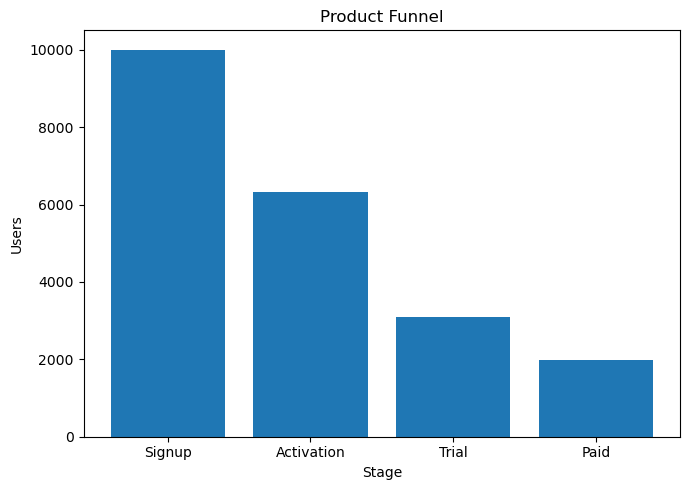

In [8]:
plt.figure(figsize=(7, 5))
plt.bar(funnel["stage"], funnel["users"])
plt.title("Product Funnel")
plt.xlabel("Stage")
plt.ylabel("Users")
plt.tight_layout()
plt.show()


## 8. Export Power BI-ready tables


In [9]:
kpi_summary.to_csv(processed / "kpi_summary.csv", index=False)
funnel.to_csv(processed / "funnel_summary.csv", index=False)
monthly_signups.to_csv(processed / "monthly_signups.csv", index=False)
monthly_paid.to_csv(processed / "monthly_paid_users.csv", index=False)
mrr_by_plan.to_csv(processed / "mrr_by_plan.csv", index=False)
revenue_by_channel.to_csv(processed / "revenue_by_channel.csv", index=False)
churn_by_plan.to_csv(processed / "churn_by_plan.csv", index=False)
cohort.to_csv(processed / "signup_cohort_summary.csv", index=False)

print("Power BI exports complete.")


Power BI exports complete.


## 9. Final Business Findings

Fill this section after running the analysis.

Structure each finding as:

**Finding → Evidence → Business implication → Recommendation**

Already validated earlier in the project:
- Activation → Trial is the largest relative funnel drop-off.
- Paid Search has weaker activation performance.
- Mobile activation trails Desktop.
- Paid Search Mobile is a particularly weak activation segment.
- Company-size differences are comparatively small.

Add feature, churn, revenue and cohort findings only after running this notebook.
